# 04 · Evaluasi Model dan Tuning Hybrid Switching

Langkah di notebook ini:

1. **Tuning hybrid** di data **validasi**: memilih ambang $\tau$ dan bobot $\alpha_\text{low}$, $\alpha_\text{high}$.
2. **Fit** semua model pada data latih.
3. **Evaluasi** sekali di data **uji**:
   - prediksi rating → RMSE, MAE;
   - kualitas Top-10 → Precision@10, Recall@10, HitRate@10, Coverage;
   - analisis per kelompok aktivitas user.
4. **Simpan artefak** untuk dashboard Streamlit.

> Semua langkah ini juga bisa dijalankan sekaligus dengan `python -m src.pipeline` dari folder proyek.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import config as C, data_prep as D, models as M, evaluation as E, pipeline as P

COLORS = {"Popularitas": "#9a9893", "Rule-Based (Association Rules)": "#eda100", "Content-Based": "#1baf7a",
          "Item-based CF": "#6250d6", "SVD (Matrix Factorization)": "#e87ba4",
          "PureSVD (Truncated SVD)": "#2a78d6", "Hybrid Switching": "#eb6834"}
plt.rcParams["axes.spines.top"] = plt.rcParams["axes.spines.right"] = False
pd.set_option("display.width", 160)

data = P.prepare()
print(f"{data['summary']['model_ratings']:,} rating | latih {len(data['train']):,} | uji {len(data['test']):,}")

130,559 rating | latih 105,091 | uji 25,463


## 1. Metrik evaluasi

**Prediksi rating** (skala 1–10), pada pasangan (user, buku) di data uji:

$$\text{RMSE}=\sqrt{\frac1n\sum(r_{ui}-\hat r_{ui})^2}\qquad \text{MAE}=\frac1n\sum|r_{ui}-\hat r_{ui}|$$

**Top-N** — untuk tiap user, model memilih 10 buku dari semua buku yang **belum** ada di riwayat latihnya. Buku **relevan** = buku di data uji dengan rating ≥ 8 ("disukai").

$$\text{Precision@10}=\frac{|\text{Top-10}\cap\text{relevan}|}{10}\qquad \text{Recall@10}=\frac{|\text{Top-10}\cap\text{relevan}|}{|\text{relevan}|}$$

- **HitRate@10** = proporsi user yang minimal satu buku relevannya masuk Top-10.
- **Coverage** = proporsi katalog yang pernah direkomendasikan ke minimal satu user (keberagaman).

## 2. Tuning hybrid di data validasi

Data latih dibagi lagi (per user) menjadi *latih-dalam* dan *validasi*. Untuk setiap $\alpha \in \{0; 0{,}2; \dots; 1\}$ ($\alpha$ = porsi Content-Based, $1-\alpha$ = porsi PureSVD) dihitung Precision@10 per user. Hasilnya lalu dikelompokkan menurut jumlah rating latih user.

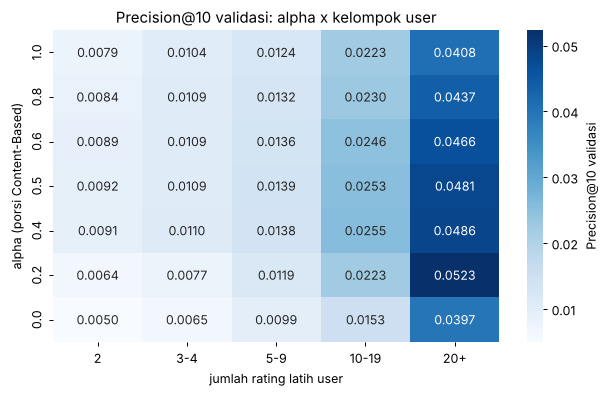

In [2]:
tr2, va, idx2 = P.validation_split(data["train"])
best, grid, act = P.tune_hybrid(tr2, va, idx2, data["books"])

piv = act.pivot(index="alpha", columns="aktivitas", values="precision")
piv = piv[[c for c in E.ACTIVITY_LABELS if c in piv.columns]].sort_index(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(piv, annot=True, fmt=".4f", cmap="Blues", cbar_kws={"label": "Precision@10 validasi"}, ax=ax)
ax.set(xlabel="jumlah rating latih user", ylabel="alpha (porsi Content-Based)",
       title="Precision@10 validasi: alpha x kelompok user");

**Cara membaca heatmap:**

- Baris **α = 1** (Content-Based saja) dan **α = 0** (PureSVD saja) hampir selalu **kalah** dari α di antaranya → menggabungkan kedua pendekatan memang membantu (inti dari *hybrid*).
- Pada user dengan riwayat sedikit, α terbaik ±0,4–0,5. Pada user dengan **20+ rating**, α terbaik turun ke **0,2** (porsi CF lebih besar). Inilah dasar **switching**: bobot berpindah sesuai banyaknya riwayat.

Sekarang cari kombinasi $(\tau, \alpha_\text{low}, \alpha_\text{high})$ dengan Precision@10 validasi tertinggi:

In [3]:
print("Terbaik:", {k: round(float(v), 4) for k, v in best.items()})
same = grid[grid["alpha_low"] == grid["alpha_high"]].iloc[0]
print(f"Tanpa switching (alpha sama untuk semua) terbaik: alpha = {same['alpha_low']}, "
      f"Precision@10 = {same['precision@10']:.4f}")
print(f"Tambahan dari switching: {best['precision@10'] / same['precision@10'] - 1:+.1%}")
grid.sort_values("precision@10", ascending=False).groupby("threshold").head(1).sort_values("threshold").round(4)

Terbaik: {'threshold': 20.0, 'alpha_low': 0.4, 'alpha_high': 0.2, 'precision@10': 0.0176}
Tanpa switching (alpha sama untuk semua) terbaik: alpha = 0.4, Precision@10 = 0.0172
Tambahan dari switching: +2.4%


,threshold,alpha_low,alpha_high,precision@10
3,3,0.5,0.4,0.0172
6,5,0.4,0.4,0.0172
4,10,0.5,0.4,0.0172
0,20,0.4,0.2,0.0176


Hasil: **τ = 20, α_low = 0,4, α_high = 0,2**.

| Riwayat user | Model |
|---|---|
| 0 buku | Popularitas |
| 1–19 buku | 40% Content-Based + 60% PureSVD |
| ≥ 20 buku | 20% Content-Based + 80% PureSVD |

Catatan jujur untuk laporan: switching menambah ±2% dibanding satu bobot tetap. Kenaikan **terbesar** datang dari *penggabungan* CB + CF itu sendiri (lihat heatmap). Switching tetap berguna untuk (1) cold-start total (n = 0) dan (2) memberi porsi CF lebih besar pada user aktif.

## 3. Fit semua model pada data latih

In [4]:
hybrid_params = {"threshold": int(best["threshold"]), "alpha_low": float(best["alpha_low"]),
                 "alpha_high": float(best["alpha_high"]), "k_svd": 50,
                 "precision_validasi": float(best["precision@10"])}
fitted = P.fit_all(data, hybrid_params, C.SVD_PARAMS)

[15:54:25] fit Popularitas
[15:54:25] fit Content-Based
[15:54:25] fit Item-based CF
[15:54:26] fit Bias baseline
[15:54:26] fit Funk SVD (+-30 detik)
[15:54:56] fit PureSVD
[15:54:56] Apriori / association rules


## 4. Evaluasi di data uji

### 4a. Prediksi rating

In [5]:
rating_metrics, topn, by_act = P.evaluate_all(fitted, data)
rating_metrics.round(4)

[15:55:06]   Top-N Popularitas: P@10 = 0.0035
[15:55:07]   Top-N Rule-Based (Association Rules): P@10 = 0.0112
[15:55:08]   Top-N Content-Based: P@10 = 0.0192
[15:55:08]   Top-N Item-based CF: P@10 = 0.0159
[15:55:08]   Top-N SVD (Matrix Factorization): P@10 = 0.0005
[15:55:09]   Top-N PureSVD (Truncated SVD): P@10 = 0.0159
[15:55:10]   Top-N Hybrid Switching: P@10 = 0.0226


,model,RMSE,MAE
0,Rata-rata global,1.7761,1.4051
1,Baseline bias (mu + b_u + b_i),1.5783,1.2193
2,Item-based CF,1.7363,1.2455
3,SVD (Matrix Factorization),1.5577,1.1957


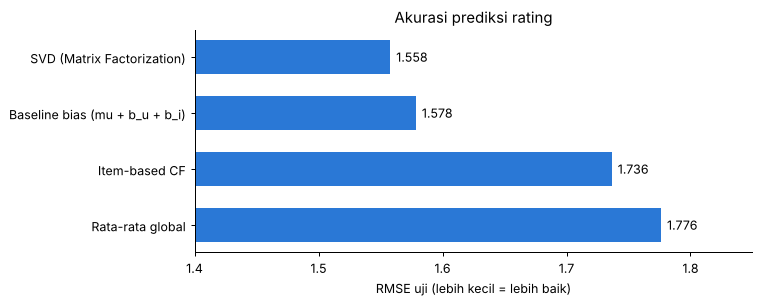

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.2))
rm = rating_metrics.sort_values("RMSE")
ax.barh(rm["model"], rm["RMSE"], color="#2a78d6", height=0.6)
for y, v in enumerate(rm["RMSE"]): ax.text(v + 0.005, y, f"{v:.3f}", va="center")
ax.set(xlim=(1.4, 1.85), xlabel="RMSE uji (lebih kecil = lebih baik)", title="Akurasi prediksi rating")
ax.invert_yaxis();

**Funk SVD** paling akurat (RMSE 1,558, turun 12% dari rata-rata global 1,776). Sebagian besar perbaikan sudah diberikan oleh **bias user & buku** (1,578); faktor laten menambah sedikit lagi. Ini wajar untuk data yang sangat jarang dan rating yang menumpuk di 7–10. Item-based CF kurang akurat karena banyak user hanya punya sedikit tetangga yang sudah ia nilai.

### 4b. Kualitas Top-10

In [7]:
topn.round(4)

,model,Precision@10,Recall@10,HitRate@10,Coverage,n_user
0,Popularitas,0.0035,0.0174,0.0322,0.0037,7893
1,Rule-Based (Association Rules),0.0112,0.0624,0.1007,0.0248,7893
2,Content-Based,0.0192,0.1032,0.1552,0.9364,7893
3,Item-based CF,0.0159,0.0780,0.1230,0.8842,7893
4,SVD (Matrix Factorization),0.0005,0.0020,0.0047,0.0136,7893
5,PureSVD (Truncated SVD),0.0159,0.0809,0.1302,0.1308,7893
6,Hybrid Switching,0.0226,0.1198,0.1774,0.8163,7893


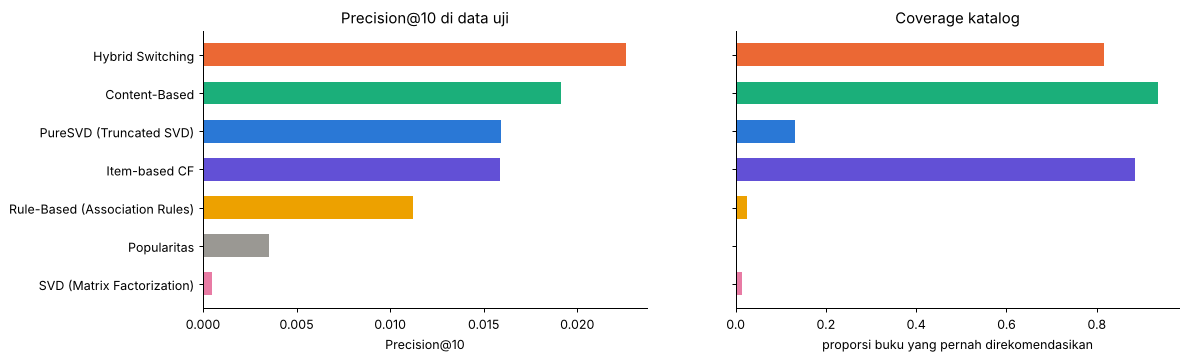

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
t = topn.sort_values("Precision@10")
ax[0].barh(t["model"], t["Precision@10"], color=[COLORS[m] for m in t["model"]], height=0.6)
ax[0].set(title="Precision@10 di data uji", xlabel="Precision@10")
ax[1].barh(t["model"], t["Coverage"], color=[COLORS[m] for m in t["model"]], height=0.6)
ax[1].set(title="Coverage katalog", xlabel="proporsi buku yang pernah direkomendasikan")
ax[1].set_yticklabels([]);

**Temuan:**

1. **Hybrid Switching terbaik**: Precision@10 0,0226 dan HitRate 17,7%, yaitu +18% precision dibanding Content-Based saja dan +42% dibanding PureSVD saja.
2. **Funk SVD hampir gagal di Top-N** (0,0005) padahal RMSE-nya terbaik. Model yang dioptimalkan untuk *nilai* rating belum tentu baik untuk *peringkat*. Fenomena ini juga dilaporkan Cremonesi dkk. (2010), dan itulah alasan PureSVD yang dipakai di dalam hybrid.
3. **Popularitas** tidak personal: coverage hanya ±0,4% (semua user mendapat ±20 buku yang sama).
4. **Rule-Based** precision-nya lumayan, tetapi coverage-nya kecil karena hanya mencakup 300 buku populer.
5. **Content-Based** kuat karena pembaca Book-Crossing setia pada penulis/seri.

> Kenapa angka precision kecil? Model memilih 10 dari ±5.650 buku, dan rata-rata user hanya punya ±2 buku relevan di data uji. Tebakan acak menghasilkan Precision@10 ≈ 0,00036; hybrid ±60 kali lebih baik. Yang penting adalah **perbandingan antar model** pada data uji yang sama.

### 4c. Menurut aktivitas user

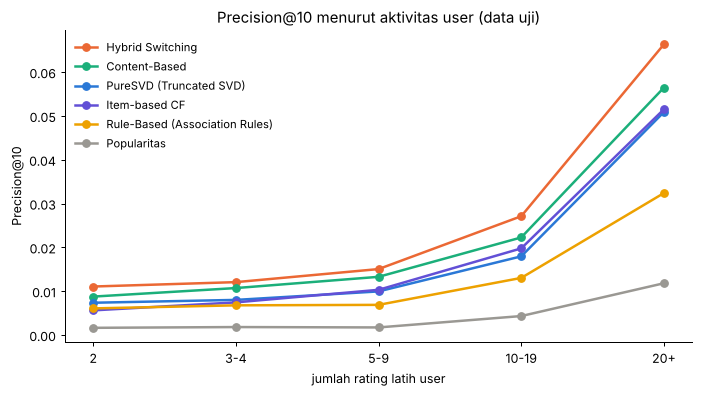

aktivitas,2,3-4,5-9,10-19,20+
model,,,,,
Content-Based,0.0088,0.0107,0.0133,0.0223,0.0565
Hybrid Switching,0.0111,0.0121,0.0150,0.0271,0.0663
Item-based CF,0.0056,0.0074,0.0103,0.0198,0.0515
Popularitas,0.0016,0.0018,0.0017,0.0043,0.0118
PureSVD (Truncated SVD),0.0074,0.0080,0.0099,0.0179,0.0509
Rule-Based (Association Rules),0.0061,0.0068,0.0069,0.0130,0.0324
SVD (Matrix Factorization),0.0002,0.0001,0.0003,0.0008,0.0015


In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for m in ["Hybrid Switching", "Content-Based", "PureSVD (Truncated SVD)", "Item-based CF", "Rule-Based (Association Rules)", "Popularitas"]:
    d = by_act[by_act["model"] == m]
    ax.plot(d["aktivitas"].astype(str), d["precision"], marker="o", lw=2, ms=6, color=COLORS[m], label=m)
ax.set(xlabel="jumlah rating latih user", ylabel="Precision@10", title="Precision@10 menurut aktivitas user (data uji)")
ax.legend(frameon=False, fontsize=9);
by_act.pivot(index="model", columns="aktivitas", values="precision")[E.ACTIVITY_LABELS].round(4)

Semua model membaik saat riwayat user bertambah, dan hybrid unggul di **semua** kelompok. Untuk user dengan 20+ rating, PureSVD dan Item-CF mendekati Content-Based; hybrid dengan porsi CF 80% memanfaatkan hal ini.

## 5. Contoh: satu user

In [10]:
index, R = data["index"], fitted["R"]
catalog = P.books_in_order(data["books"], index)
test_rel = data["test"][data["test"]["rating"] >= 8]
cand = [u for u in test_rel["user_id"].unique() if 20 <= np.diff(R.indptr)[index.u2i[u]] <= 40]
uid = cand[3]
u = index.u2i[uid]
hist = R[u]
print(f"User {uid}: {hist.nnz} buku di riwayat latih")
print(fitted["hybrid"].choose(hist.nnz)[1])
print("\nContoh riwayat (rating tertinggi):")
for j in hist.indices[np.argsort(-hist.data)][:6]:
    print("  -", catalog.loc[j, "title"][:60], "|", catalog.loc[j, "author"])
rel_items = set(test_rel.loc[test_rel["user_id"] == uid, "book_id"])
top = M.top_n(fitted["hybrid"].score_users(np.array([u]))[0], exclude=hist.indices, n=10)
pd.DataFrame({"rekomendasi hybrid": catalog.loc[top, "title"].str.slice(0, 55).values,
              "penulis": catalog.loc[top, "author"].values,
              "prediksi rating (Funk SVD)": fitted["svd"].predict_many(np.full(10, u), top).round(2),
              "disukai di data uji?": ["✅" if b in rel_items else "" for b in catalog.loc[top, "book_id"]]})

User 251140: 34 buku di riwayat latih
Riwayat 34 buku (>= 20) -> 20% Content-Based + 80% Collaborative (PureSVD)

Contoh riwayat (rating tertinggi):
  - Young Wives | Olivia Goldsmith
  - Bridget Jones's Diary | Helen Fielding
  - Of Mice and Men (Penguin Great Books of the 20th Century) | John Steinbeck
  - The Grapes of Wrath | John Steinbeck
  - Welcome to Temptation | Jennifer Crusie
  - Tell Me Lies (Tell Me Lies) | Jennifer Crusie


,rekomendasi hybrid,penulis,prediksi rating (Funk SVD),disukai di data uji?
0,I Know This Much Is True,Wally Lamb,8.78,
1,East of Eden (Oprah's Book Club),John Steinbeck,8.72,
2,Bridget Jones: The Edge of Reason,Helen Fielding,8.24,✅
3,The Book of Ruth (Oprah's Book Club (Paperback)),Jane Hamilton,8.31,
4,Songs in Ordinary Time (Oprah's Book Club (Pap...,Mary McGarry Morris,7.34,
5,Bet Me,Jennifer Crusie,8.62,
6,The Pilot's Wife : A Novel Tag: Author of the ...,Anita Shreve,8.31,
7,Vinegar Hill (Oprah's Book Club (Paperback)),A. Manette Ansay,7.55,
8,Faking It,Jennifer Crusie,8.12,✅
9,Confessions of a Shopaholic (Summer Display Op...,SOPHIE KINSELLA,8.43,✅


## 6. Simpan artefak untuk dashboard

Model disimpan sebagai file `.npz` / `.npy` / `.csv.gz` di folder `models/` dan `data/processed/`. Dashboard hanya **memuat** file-file ini, tanpa melatih ulang, sehingga aplikasinya cepat.

In [11]:
tuning = {"hybrid_grid": grid, "hybrid_alpha_activity": act}
svd_tuning = C.MODEL_DIR / "tuning_svd.csv"
if svd_tuning.exists():          # hasil tuning SVD dari pipeline (jika sudah pernah dijalankan)
    tuning["svd"] = pd.read_csv(svd_tuning)
P.save_artifacts(data, fitted, hybrid_params, (rating_metrics, topn, by_act), tuning, P.eda_tables(data))
sorted(p.name for p in C.MODEL_DIR.iterdir())

[15:55:12] artefak tersimpan di models dan data/processed


['R_train.npz', 'catalog.csv.gz', 'cb_tfidf.npz', 'eval_by_activity.csv', 'eval_rating.csv', 'eval_topn.csv', 'funksvd.npz', 'itemcf_sim.npz', 'itemcf_user_mean.npy', 'meta.json', 'popularity_meta.npy', 'puresvd_V.npy', 'rules.csv.gz', 'tuning_hybrid_alpha_activity.csv', 'tuning_hybrid_grid.csv', 'tuning_svd.csv', 'users_index.csv.gz']

## 7. Menjalankan dashboard

Dari **folder proyek** (bukan folder `notebooks/`), jalankan di terminal:

```bash
streamlit run app/Beranda.py
```

Browser akan terbuka di `http://localhost:8501`.

## Ringkasan untuk laporan

| Tugas | Model terbaik | Angka (data uji) |
|---|---|---|
| Prediksi nilai rating | Funk SVD (k = 20, λ = 0,15) | RMSE 1,558 · MAE 1,196 |
| Rekomendasi Top-10 | **Hybrid Switching** (CB + PureSVD) | Precision@10 0,0226 · Recall@10 0,120 · HitRate 17,7% |

**Keterbatasan & pengembangan:**
- Fitur konten hanya judul/penulis/penerbit, tanpa genre/sinopsis. Menambah metadata (misalnya dari Open Library) kemungkinan memperkuat Content-Based.
- Tidak ada *timestamp*, jadi split dilakukan acak per user, bukan berdasarkan waktu, dan *context-aware rules* tidak bisa dibuat.
- Relevansi diukur hanya dari buku yang kebetulan dinilai user di data uji. Buku bagus yang belum pernah ia temui dihitung "salah", sehingga precision cenderung *underestimate*.
- Pengembangan: model implicit-feedback (mis. ALS untuk data 0/1), atau bobot α yang berubah halus sebagai fungsi jumlah riwayat.